<a href="https://colab.research.google.com/github/Ten-Son7/Analysis-of-Ford-s-Relationship-to-car-injuries/blob/main/Code_Group4_Main.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# 0. Import packages & Connect to Drive
# ============================================================

from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ============================================================
# 1. Load data
# ============================================================

drive_path = '/content/drive/MyDrive/Group 4 Project CIS9660/'
file_name = 'MotorVehicle.csv'

df = pd.read_csv(
    drive_path + file_name,
    low_memory=False
)

print("Original shape:", df.shape)
print(df.head())

Original shape: (89102, 27)
   UNIQUE_ID  COLLISION_ID CRASH_DATE CRASH_TIME VEHICLE_ID  \
0   17031445       3405265  3/19/2016      14:21     203530   
1   17031446       3405265  3/19/2016      14:21     203531   
2   16937807       3405925  3/22/2016       5:40     161407   
3   16945123       3406511  3/22/2016      11:06      32875   
4   16946723       3406521  3/24/2016      15:30      38027   

  STATE_REGISTRATION VEHICLE_TYPE    VEHICLE_MAKE VEHICLE_MODEL  VEHICLE_YEAR  \
0                 NJ   4 dr sedan   NISS -CAR/SUV           NaN        2014.0   
1                 NJ          NaN  MITS-TRUCK/BUS           NaN        2010.0   
2                 NY          NaN   FORD -CAR/SUV           NaN        1997.0   
3                NaN          NaN             NaN           NaN           NaN   
4                 CT          NaN    BMW -CAR/SUV           NaN        2013.0   

   ...           VEHICLE_DAMAGE  VEHICLE_DAMAGE_1 VEHICLE_DAMAGE_2  \
0  ...  Left Rear Quarter Panel     

In [ ]:
# ============================================================
# 2. Create key outcome variables
# ============================================================

df['fatal'] = (
    pd.to_numeric(df['NUMBER OF PERSONS KILLED'], errors='coerce')
    .fillna(0)
    .gt(0)
    .astype(int)
)

df['injured_count'] = pd.to_numeric(
    df['NUMBER OF PERSONS INJURED'],
    errors='coerce'
).fillna(0)

df['injured'] = (
    df['injured_count']
    .gt(0)
    .astype(int)
)

df['ford'] = (
    df['VEHICLE_MAKE']
    .astype(str)
    .str.contains('FORD', case=False, na=False)
    .astype(int)
)

df['CRASH_DATE'] = pd.to_datetime(df['CRASH_DATE'], errors='coerce')
df['year'] = df['CRASH_DATE'].dt.year

df['hour'] = pd.to_datetime(
    df['CRASH_TIME'],
    format='%H:%M',
    errors='coerce'
).dt.hour

# Keep 2016 only
df = df[df['year'] == 2016].copy()

print("\n===== 2016 DATA CHECK =====")
print("2016-only shape:", df.shape)
print("Fatal rows:", int(df['fatal'].sum()))
print("Injured rows:", int(df['injured'].sum()))
print("Ford rows:", int(df['ford'].sum()))


===== 2016 DATA CHECK =====
2016-only shape: (87430, 33)
Fatal rows: 46
Injured rows: 16219
Ford rows: 8044


Step 2. Note: The three main variables that the analysis depends on
* fatal (whether someone died)
  * 'NUMBER OF PERSONS KILLED' column to numeric format fills any missing values with 0.
* injured (whether someone was injured)
* ford (whether the vehicle is a Ford)
  * VEHICLE_MAKE column contains the text "FORD" (case-insensitive, so "Ford," "FORD," "ford" all match).

 These binary indicators are derived from the original dataset's columns and will serve as our outcome variables or main predictor.


This step also creates a year variable and hour variable from the date/time columns, then filters the dataset to include only 2016 data for temporal consistency.

Filtering to 2016 Only. The .copy() ensures we work with a new dataframe rather than a reference to the original. Restricting to 2016 makes the analysis cleaner and more focused.

In [ ]:
# ============================================================
# 3. Clean and group VEHICLE_TYPE
# ============================================================

def clean_vehicle_type(v):
    v = str(v).upper().strip()

    if v in ['', 'NAN', 'NA', 'N/A', 'UNK', 'UNKNOWN', 'UNSPECIFIED', '-', '0']:
        return 'Unknown'

    if any(x in v for x in ['SEDAN', '4 DR', '4D', '2 DR', '2 DOO', 'PASS']):
        return 'Sedan'

    if any(x in v for x in ['SPORT UTILITY', 'SUV', 'STATION WAGON', 'WAGON', 'SUBUR', 'CARRY ALL']):
        return 'SUV_Wagon'

    if any(x in v for x in ['PICK', 'PK', 'PU', 'PICK-UP']):
        return 'Pickup'

    if any(x in v for x in ['VAN', 'UHAUL', 'CARGO']):
        return 'Van'

    if any(x in v for x in ['TAXI', 'LIMO']):
        return 'Taxi_Limo'

    if any(x in v for x in ['BUS', 'OMNI', 'SCHOOL BUS']):
        return 'Bus'

    if any(x in v for x in [
        'TRUCK', 'TRK', 'TRACTOR', 'DUMP', 'BOX', 'FLAT', 'TANK',
        'GARBAGE', 'REFUSE', 'MACK', 'HINO', 'FREIG', 'FREIH',
        'CONCRETE', 'TOW', 'WRECKER'
    ]):
        return 'Truck_Commercial'

    if any(x in v for x in ['MOTORCYCLE', 'MOTORBIKE', 'MOPED', 'SCOOT']):
        return 'Motorcycle'

    if any(x in v for x in ['BIKE', 'E-BIK', 'EBIKE']):
        return 'Bike'

    if any(x in v for x in ['AMBULANCE', 'AMBU', 'EMS', 'FIRE', 'FDNY', 'NYPD', 'USPS', 'US PO', 'POSTA']):
        return 'Emergency_Gov'

    return 'Other'


df['vehicle_type_group'] = df['VEHICLE_TYPE'].apply(clean_vehicle_type)

print("\n===== VEHICLE TYPE GROUP DISTRIBUTION BEFORE CLEANING =====")
print(df['vehicle_type_group'].value_counts(dropna=False))


===== VEHICLE TYPE GROUP DISTRIBUTION BEFORE CLEANING =====
vehicle_type_group
Sedan               40444
SUV_Wagon           26365
Unknown              5745
Taxi_Limo            3698
Truck_Commercial     3420
Pickup               2730
Bus                  1393
Bike                 1283
Van                   891
Other                 702
Motorcycle            474
Emergency_Gov         285
Name: count, dtype: int64


Step 3. Note:

This step consolidates the fragmented VEHICLE_TYPE variable (which had 50+ different entries, too irregular, scratchy, and duplicates)—all meaning the same thing but recorded differently.

Now it is into 10 broad, meaningful categories.

For example, if the entry contains "SEDAN" or "4 DR" or "PASSENGER," it's classified as Sedan. If it contains "SUV" or "STATION WAGON," it becomes SUV_Wagon. The function checks multiple spelling variations and abbreviations (like PK for pickup).

Entries that don't match any pattern go into "Other." Missing or unclear entries become "Unknown."

In [ ]:
# ============================================================
# 4. Strict cleaning before sampling
# ============================================================

df_clean = df.copy()

df_clean['VEHICLE_YEAR'] = pd.to_numeric(
    df_clean['VEHICLE_YEAR'],
    errors='coerce'
)

df_clean['VEHICLE_OCCUPANTS'] = pd.to_numeric(
    df_clean['VEHICLE_OCCUPANTS'],
    errors='coerce'
)

# Required fields for final models
required_cols = [
    'VEHICLE_MAKE',
    'VEHICLE_YEAR',
    'VEHICLE_OCCUPANTS',
    'CRASH_DATE',
    'hour',
    'vehicle_type_group',
    'NUMBER OF PERSONS INJURED',
    'NUMBER OF PERSONS KILLED'
]

df_clean = df_clean.dropna(subset=required_cols).copy()

# Remove unknown vehicle type for cleaner model
df_clean = df_clean[df_clean['vehicle_type_group'] != 'Unknown'].copy()

# Fill driver fields instead of dropping rows
df_clean['DRIVER_SEX'] = df_clean['DRIVER_SEX'].fillna('Unknown')
df_clean['DRIVER_LICENSE_STATUS'] = df_clean['DRIVER_LICENSE_STATUS'].fillna('Unknown')
df_clean['DRIVER_LICENSE_JURISDICTION'] = df_clean['DRIVER_LICENSE_JURISDICTION'].fillna('Unknown')

print("\n===== STRICT CLEANING CHECK =====")
print("Rows:", len(df_clean))
print("Fatal rows:", int(df_clean['fatal'].sum()))
print("Injured rows:", int(df_clean['injured'].sum()))
print("Ford rows:", int(df_clean['ford'].sum()))


===== STRICT CLEANING CHECK =====
Rows: 76713
Fatal rows: 40
Injured rows: 13823
Ford rows: 7830


Step 4. Note:

This step removes rows with missing values in essential modeling variables and eliminates unknown vehicle types. This ensures the dataset is clean before the strategic sampling step.

It converts VEHICLE_YEAR and VEHICLE_OCCUPANTS to numeric format (replacing non-numeric entries with NaN). Then it drops all rows that have missing values in any of the required columns. Finally, it removes rows where the vehicle type is "Unknown" (since we can't meaningfully classify those).

Logit regression cannot handle missing values—any row with a missing value in any variable will be automatically dropped during model estimation, which can reduce sample size unpredictably. By cleaning now, we know exactly how many observations we have.

This cleaning removes ~12% of the original data, but the remaining data is clean and suitable for modeling.

For three driver-related columns (sex, license status, and license jurisdiction), any missing values are replaced with the string 'Unknown'. This creates a category for missing data rather than deleting those rows. We could have deleted these rows instead, but that would lose ~1,000+ observations.  

Filling with "Unknown" is more data-efficient while still being honest about the missingness.

In [ ]:
# ============================================================
# 5. Final 60000s sample
#    Preserve all fatal rows
#    Preserve all injured rows
#    Fill remaining rows with nonfatal / non-injured rows
# ============================================================

target_n = 60000

# 1. Preserve all rows with fatal or injured outcomes
# This keeps all severe crash observations.
key_df = df_clean[
    (df_clean['fatal'] == 1) |
    (df_clean['injured'] == 1)
].copy()

# 2. Nonfatal and non-injured rows
other_df = df_clean[
    (df_clean['fatal'] == 0) &
    (df_clean['injured'] == 0)
].copy()

# 3. Fill the remaining sample with nonfatal / non-injured rows
remaining_n = target_n - len(key_df)

if remaining_n < 0:
    print("Warning: fatal + injured rows already exceed target_n.")
    print("Using all fatal/injured rows without adding non-injured rows.")
    df_model = key_df.copy()

elif len(other_df) > remaining_n:
    other_sample = other_df.sample(
        n=remaining_n,
        random_state=1
    )

    df_model = pd.concat(
        [key_df, other_sample],
        ignore_index=True
    )

else:
    print("Warning: Not enough non-injured rows to reach target_n.")
    print("Using all available cleaned rows.")
    df_model = pd.concat(
        [key_df, other_df],
        ignore_index=True
    )

# 4. Shuffle final sample
df_model = df_model.sample(frac=1, random_state=1).reset_index(drop=True)

print("\n===== FINAL 60000s MODEL DATASET =====")
print("Rows:", len(df_model))
print("Fatal rows:", int(df_model['fatal'].sum()))
print("Injured rows:", int(df_model['injured'].sum()))
print("Non-injured rows:", int((df_model['injured'] == 0).sum()))
print("Ford rows:", int(df_model['ford'].sum()))
print("Non-Ford rows:", int((df_model['ford'] == 0).sum()))
print("Fatal rate:", round(df_model['fatal'].mean(), 6))
print("Injury rate:", round(df_model['injured'].mean(), 6))
print("Ford share:", round(df_model['ford'].mean(), 4))

print("\n===== VEHICLE TYPE DISTRIBUTION IN FINAL SAMPLE =====")
print(df_model['vehicle_type_group'].value_counts(dropna=False))


===== FINAL 60000s MODEL DATASET =====
Rows: 60000
Fatal rows: 40
Injured rows: 13823
Non-injured rows: 46177
Ford rows: 6144
Non-Ford rows: 53856
Fatal rate: 0.000667
Injury rate: 0.230383
Ford share: 0.1024

===== VEHICLE TYPE DISTRIBUTION IN FINAL SAMPLE =====
vehicle_type_group
Sedan               30683
SUV_Wagon           19885
Taxi_Limo            2788
Truck_Commercial     2276
Pickup               1917
Bus                   940
Van                   576
Other                 447
Motorcycle            350
Emergency_Gov         135
Bike                    3
Name: count, dtype: int64


In [ ]:
# ============================================================
# 5.1 Summary table for final 60000s sample
# ============================================================

summary_table = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Ford Rows',
        'Non-Ford Rows',
        'Fatal Rows',
        'Nonfatal Rows',
        'Injured Rows',
        'Non-Injured Rows',
        'Fatal Rate',
        'Injury Rate',
        'Ford Share'
    ],
    'Value': [
        len(df_model),
        int(df_model['ford'].sum()),
        int((df_model['ford'] == 0).sum()),
        int(df_model['fatal'].sum()),
        int((df_model['fatal'] == 0).sum()),
        int(df_model['injured'].sum()),
        int((df_model['injured'] == 0).sum()),
        round(df_model['fatal'].mean(), 6),
        round(df_model['injured'].mean(), 6),
        round(df_model['ford'].mean(), 4)
    ]
})

print("\n===== SUMMARY TABLE =====")
print(summary_table)


===== SUMMARY TABLE =====
             Metric         Value
0        Total Rows  60000.000000
1         Ford Rows   6144.000000
2     Non-Ford Rows  53856.000000
3        Fatal Rows     40.000000
4     Nonfatal Rows  59960.000000
5      Injured Rows  13823.000000
6  Non-Injured Rows  46177.000000
7        Fatal Rate      0.000667
8       Injury Rate      0.230383
9        Ford Share      0.102400


Step 5. (and 5.1) Note:

It creates the final analysis dataset by preserving all rare fatal cases while sampling from more common cases

This separates the cleaned dataset into three groups: fatal crashes, injured-but-not-fatal crashes, and nonfatal-non-injured crashes. It then keeps ALL fatal crashes (all 40), samples a subset of injured crashes (3,500 out of ~13,823), and fills the remaining rows with nonfatal-non-injured cases. The three groups are concatenated back together and shuffled randomly. The random_state=1 ensures reproducible results.

Fatal crashes are extremely rare (~0.05% of crashes). If we randomly sampled to 6,500 observations, we'd expect only about 3-4 fatal cases—too few for meaningful regression analysis. By preserving all 40 fatal cases, we ensure the model can learn about fatalities. Injured cases are more common but still important, so we sample some (not all) to avoid overfitting to injuries. Nonfatal-non-injured cases are abundant, so we use them to fill remaining slots.

After combining the three groups, the data would be ordered (all fatals, then all injured, then all non-injured). Shuffling with random_state=1 randomizes the order while keeping results reproducible. This prevents the model from learning patterns based on data ordering.

Because the intended sample size was approximately 60,000 rather than 6,000, we preserved all fatal and injured observations. We then randomly sampled from nonfatal and non-injured observations to fill the remaining rows up to the target sample size. This keeps all severe crash outcomes while reducing the cleaned dataset only moderately.

In [ ]:
# ============================================================
# 6. Create model variables
# ============================================================

df_model['male'] = (
    df_model['DRIVER_SEX']
    .astype(str)
    .str.upper()
    .eq('M')
    .astype(int)
)

df_model['licensed'] = (
    df_model['DRIVER_LICENSE_STATUS']
    .astype(str)
    .str.contains('Licensed', case=False, na=False)
    .astype(int)
)

factor_cols = ['CONTRIBUTING_FACTOR_1', 'CONTRIBUTING_FACTOR_2']

df_model['unsafe_speed'] = (
    df_model[factor_cols]
    .fillna('')
    .astype(str)
    .apply(lambda row: row.str.contains('Unsafe Speed', case=False, na=False).any(), axis=1)
    .astype(int)
)

df_model['driver_inattention_v2'] = (
    df_model[factor_cols]
    .fillna('')
    .astype(str)
    .apply(lambda row: row.str.contains('Driver Inattention/Distraction', case=False, na=False).any(), axis=1)
    .astype(int)
)

df_model['age_of_vehicle'] = df_model['year'] - df_model['VEHICLE_YEAR']
df_model.loc[df_model['age_of_vehicle'] < 0, 'age_of_vehicle'] = np.nan
df_model['age_of_vehicle'] = df_model['age_of_vehicle'].fillna(df_model['age_of_vehicle'].median())

df_model['old_vehicle_10plus'] = (
    df_model['age_of_vehicle'] >= 10
).astype(int)

df_model['occupants_3plus'] = (
    df_model['VEHICLE_OCCUPANTS'] >= 3
).astype(int)

# ========== TIME-OF-DAY CATEGORIES ==========
# Divide 24 hours into 5 meaningful periods (non-linear)

def assign_time_of_day(hour):
    if pd.isna(hour):
        return np.nan
    hour = int(hour)

    if 6 <= hour < 12:
        return 1  # Morning (6am-12pm)
    elif 12 <= hour < 17:
        return 2  # Afternoon (12pm-5pm)
    elif 17 <= hour < 22:
        return 3  # Evening (5pm-10pm)
    elif 22 <= hour < 24 or (0 <= hour < 1):
        return 4  # Night (10pm-1am)
    else:  # 1 <= hour < 6
        return 5  # Late Night (1am-6am)

df_model['time_of_day'] = df_model['hour'].apply(assign_time_of_day)

# Keep your existing peak/late-night variables
df_model['peak_hour'] = (
    df_model['hour'].isin([7, 8, 9, 16, 17, 18, 19])
).astype(int)

df_model['late_night_v2'] = (
    df_model['hour'].isin([22, 23, 0, 1, 2, 3, 4, 5])
).astype(int)

# Verification
print("\nTime-of-Day Distribution:")
print(df_model['time_of_day'].value_counts().sort_index())
print(f"Missing: {df_model['time_of_day'].isna().sum()}")

df_model['crash_month'] = df_model['CRASH_DATE'].dt.month

df_model['crash_month'] = pd.to_datetime(
    df_model['CRASH_DATE'],
    errors='coerce'
).dt.month

df_model['spring'] = df_model['crash_month'].isin([3, 4, 5]).astype(int)
df_model['summer'] = df_model['crash_month'].isin([6, 7, 8]).astype(int)
df_model['fall'] = df_model['crash_month'].isin([9, 10, 11]).astype(int)
df_model['winter'] = df_model['crash_month'].isin([12, 1, 2]).astype(int)

print("\n===== SEASON DUMMY CHECK =====")
print("Spring:", df_model['spring'].sum())
print("Summer:", df_model['summer'].sum())
print("Fall:", df_model['fall'].sum())
print("Winter:", df_model['winter'].sum())

print("\nEach row should belong to exactly one season:")
print((df_model[['spring', 'summer', 'fall', 'winter']].sum(axis=1)).value_counts())

df_model['nystate_driver'] = (
    df_model['DRIVER_LICENSE_JURISDICTION']
    .astype(str)
    .str.upper()
    .eq('NY')
    .astype(int)
)

df_model['day_of_week'] = df_model['CRASH_DATE'].dt.dayofweek

df_model['weekend'] = (
    df_model['day_of_week'].isin([5, 6])
).astype(int)

# ============================================================
# Passenger-in-car dummy variable
# 1 if more than one person was in the vehicle, 0 otherwise
# ============================================================

df_model['passengers_in_car'] = (
    df_model['VEHICLE_OCCUPANTS'] > 1
).astype(int)

print("\n===== PASSENGERS IN CAR CHECK =====")
print(df_model['passengers_in_car'].value_counts(dropna=False))

# passengers_in_car = 1 if VEHICLE_OCCUPANTS > 1
# passengers_in_car = 0 if VEHICLE_OCCUPANTS <= 1

print("\n===== MODEL VARIABLE DISTRIBUTIONS =====")
model_vars_check = [
    'ford',
    'fatal',
    'injured',
    'unsafe_speed',
    'time_of_day',
    'peak_hour',
    'late_night_v2',
    'male',
    'licensed',
    'occupants_3plus',
    'old_vehicle_10plus',
    'driver_inattention_v2',
    'weekend',
    'nystate_driver'
]

for col in model_vars_check:
    print(f"\n{col}")
    print(df_model[col].value_counts(dropna=False))


Time-of-Day Distribution:
time_of_day
1    16169
2    18645
3    15640
4     5595
5     3951
Name: count, dtype: int64
Missing: 0

===== SEASON DUMMY CHECK =====
Spring: 49
Summer: 4167
Fall: 42029
Winter: 13755

Each row should belong to exactly one season:
1    60000
Name: count, dtype: int64

===== PASSENGERS IN CAR CHECK =====
passengers_in_car
0    46436
1    13564
Name: count, dtype: int64

===== MODEL VARIABLE DISTRIBUTIONS =====

ford
ford
0    53856
1     6144
Name: count, dtype: int64

fatal
fatal
0    59960
1       40
Name: count, dtype: int64

injured
injured
0    46177
1    13823
Name: count, dtype: int64

unsafe_speed
unsafe_speed
0    58955
1     1045
Name: count, dtype: int64

time_of_day
time_of_day
2    18645
1    16169
3    15640
4     5595
5     3951
Name: count, dtype: int64

peak_hour
peak_hour
0    35990
1    24010
Name: count, dtype: int64

late_night_v2
late_night_v2
0    50454
1     9546
Name: count, dtype: int64

male
male
1    38032
0    21968
Name: count, 

Step 6. Note:

This step creates binary indicators from the raw data for use in logit regression. Each variable is a 0/1 indicator capturing a specific characteristic or behavior.

The male variable checks if driver sex equals "M" (after converting to uppercase for consistency). The licensed variable checks if the license status contains the word "Licensed" (case-insensitive, so "Licensed," "LICENSED," etc. all match). Both convert the True/False result to 1/0.

The dataset has two contributing factor columns (CONTRIBUTING_FACTOR_1 and CONTRIBUTING_FACTOR_2). This code checks if EITHER of these columns contains the phrase "Unsafe Speed" or "Driver Inattention/Distraction."

Vehicle age is calculated as the crash year minus the vehicle year (e.g., 2016 - 2006 = 10 years old). Any negative ages (impossible—vehicle year after crash year, likely data errors) are set to missing. Missing values are then filled with the median age. Finally, a binary indicator is created for vehicles 10+ years old.

Occupancy is a binary indicator for 3+ people in the vehicle. Peak hour flags crashes between 7-9am and 4-7pm (commute times). Late night flags crashes between 10pm-5am.

Season is assigned numeric values (1=Spring through 4=Winter) based on the crash month. Missing seasons are filled with the median season.

NY state driver is a binary for drivers licensed in New York.

Weekend flags Saturday (5) and Sunday (6).

In [ ]:
# ============================================================
# 7. Create simplified vehicle type controls
#    Use a few broad dummies to avoid duplicate columns and logit instability
# ============================================================

# Remove any old type_ columns before creating new ones
old_type_cols = [col for col in df_model.columns if col.startswith('type_')]
df_model = df_model.drop(columns=old_type_cols, errors='ignore')

df_model['type_suv_wagon'] = (
    df_model['vehicle_type_group'] == 'SUV_Wagon'
).astype(int)

df_model['type_taxi_limo'] = (
    df_model['vehicle_type_group'] == 'Taxi_Limo'
).astype(int)

df_model['type_commercial'] = (
    df_model['vehicle_type_group'].isin([
        'Truck_Commercial',
        'Pickup',
        'Van',
        'Bus'
    ])
).astype(int)

# Reference group is mainly Sedan / Other / small rare types
vehicle_type_cols = [
    'type_suv_wagon',
    'type_taxi_limo',
    'type_commercial'
]

print("\n===== SIMPLIFIED VEHICLE TYPE CONTROLS =====")
print(df_model[vehicle_type_cols].sum())


===== SIMPLIFIED VEHICLE TYPE CONTROLS =====
type_suv_wagon     19885
type_taxi_limo      2788
type_commercial     5709
dtype: int64


Step 7. Note:

This step simplifies the 10 vehicle type categories into 3 binary dummy variables for use in regression.

First, it removes any old vehicle type variables to avoid duplication. Then it creates three binary dummies: one for SUV/Wagon, one for Taxi/Limo, and one for commercial vehicles (trucks, pickups, vans, buses).

Commercial vehicles (trucks, vans, buses) are grouped together because they're all large vehicles that cause more severe crashes. SUV/Wagon are grouped as mid-size vehicles. Taxi/Limo are kept separate because they represent a distinct usage pattern (commercial driving). Sedans are the reference because they're the most common and most comparable across manufacturers.

In [ ]:
# ============================================================
# 8. Regression variable lists
# ============================================================

fatal_base_controls = [
    'ford',
    'injured',
    'unsafe_speed',
    'peak_hour',
    'late_night_v2',
    'male',
    'licensed',
    'passengers_in_car',
    'age_of_vehicle',
    'driver_inattention_v2',
    'summer',
    'winter',
    'fall',
    'weekend',
    'nystate_driver'
]


injured_base_controls = [
    'ford',
    'unsafe_speed',
    'peak_hour',
    'late_night_v2',
    'male',
    'licensed',
    'passengers_in_car',
    'age_of_vehicle',
    'driver_inattention_v2',
    'summer',
    'winter',
    'fall',
    'weekend',
    'nystate_driver'
]

fatal_regression_vars = list(dict.fromkeys(fatal_base_controls + vehicle_type_cols))
injured_regression_vars = list(dict.fromkeys(injured_base_controls + vehicle_type_cols))

print("\n===== FATAL REGRESSION VARIABLES =====")
print(fatal_regression_vars)

print("\n===== INJURED REGRESSION VARIABLES =====")
print(injured_regression_vars)

print("\n===== MISSING VALUE CHECK: FATAL MODEL =====")
print(df_model[fatal_regression_vars + ['fatal']].isna().sum())

print("\n===== MISSING VALUE CHECK: INJURED MODEL =====")
print(df_model[injured_regression_vars + ['injured']].isna().sum())


===== FATAL REGRESSION VARIABLES =====
['ford', 'injured', 'unsafe_speed', 'peak_hour', 'late_night_v2', 'male', 'licensed', 'passengers_in_car', 'age_of_vehicle', 'driver_inattention_v2', 'summer', 'winter', 'fall', 'weekend', 'nystate_driver', 'type_suv_wagon', 'type_taxi_limo', 'type_commercial']

===== INJURED REGRESSION VARIABLES =====
['ford', 'unsafe_speed', 'peak_hour', 'late_night_v2', 'male', 'licensed', 'passengers_in_car', 'age_of_vehicle', 'driver_inattention_v2', 'summer', 'winter', 'fall', 'weekend', 'nystate_driver', 'type_suv_wagon', 'type_taxi_limo', 'type_commercial']

===== MISSING VALUE CHECK: FATAL MODEL =====
ford                     0
injured                  0
unsafe_speed             0
peak_hour                0
late_night_v2            0
male                     0
licensed                 0
passengers_in_car        0
age_of_vehicle           0
driver_inattention_v2    0
summer                   0
winter                   0
fall                     0
weekend 

Step 8. Note:

This code lists all variables that will be used in each model and counts how many missing values (NaN) exist for each variable. The output shows the variable name and the count of missing values.

Logit regression in Python (statsmodels) automatically drops any row that has a missing value in any variable used in the model. If we have missing values here, we won't know until after fitting the model—at which point our sample size has unexpectedly shrunk. By checking beforehand, we ensure exactly what data we have and prevent surprises. The goal is to see all zeros.

In [ ]:
# ============================================================
# 9. Simple Logit Regression
#    fatal ~ ford
# ============================================================

X_simple = df_model[['ford']].copy()
y_simple = df_model['fatal'].copy()

X_simple = sm.add_constant(X_simple, has_constant='add')

model_simple = sm.Logit(y_simple, X_simple).fit(maxiter=100)

print("\n===== SIMPLE LOGIT REGRESSION: FATAL ~ FORD =====")
print(model_simple.summary())

simple_results = pd.DataFrame({
    'Variable': model_simple.params.index,
    'Coefficient': model_simple.params.values,
    'P_value': model_simple.pvalues.values,
    'Odds_Ratio': np.exp(model_simple.params.values)
}).round(4)

print("\n===== SIMPLE MODEL RESULTS TABLE =====")
print(simple_results)

Optimization terminated successfully.
         Current function value: 0.005514
         Iterations 11

===== SIMPLE LOGIT REGRESSION: FATAL ~ FORD =====
                           Logit Regression Results                           
Dep. Variable:                  fatal   No. Observations:                60000
Model:                          Logit   Df Residuals:                    59998
Method:                           MLE   Df Model:                            1
Date:                Tue, 05 May 2026   Pseudo R-squ.:                0.005032
Time:                        15:43:03   Log-Likelihood:                -330.84
converged:                       True   LL-Null:                       -332.52
Covariance Type:            nonrobust   LLR p-value:                   0.06735
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -7.4277      0.177    -42.005      0.000  

Step 9. Note:

This step fits a simple logit regression with ONLY ford as the predictor, no controls. This shows the raw relationship between Ford and fatal crashes without controlling for confounders.

To see the "unadjusted" relationship between Ford and fatalities,the coefficient (0.7871) is on the log-odds scale. The odds ratio (2.20) is more interpretable: Ford vehicles have 2.20× the odds of fatal crashes. The p-value (0.048) indicates this is statistically significant at the 5% level.

In [ ]:
# ============================================================
# 10. Multiple Logit Regression: Fatal outcome
#     fatal ~ ford + injured + controls + simplified vehicle type
# ============================================================

X_fatal = df_model[fatal_regression_vars].copy()
y_fatal = df_model['fatal'].copy()

X_fatal = X_fatal.apply(pd.to_numeric, errors='coerce')
y_fatal = pd.to_numeric(y_fatal, errors='coerce')

fatal_data = pd.concat([y_fatal, X_fatal], axis=1).dropna()

y_fatal_clean = fatal_data['fatal']
X_fatal_clean = fatal_data.drop(columns=['fatal'])

X_fatal_clean = sm.add_constant(X_fatal_clean, has_constant='add')

model_fatal = sm.Logit(y_fatal_clean, X_fatal_clean).fit(
    maxiter=200,
    method='lbfgs',
    disp=False
)

print("\n===== MULTIPLE LOGIT REGRESSION: FATAL OUTCOME =====")
print(model_fatal.summary())

fatal_results = pd.DataFrame({
    'Variable': model_fatal.params.index,
    'Coefficient': model_fatal.params.values,
    'P_value': model_fatal.pvalues.values,
    'Odds_Ratio': np.exp(model_fatal.params.values)
}).round(4)

print("\n===== FATAL MODEL RESULTS TABLE =====")
print(fatal_results)


===== MULTIPLE LOGIT REGRESSION: FATAL OUTCOME =====
                           Logit Regression Results                           
Dep. Variable:                  fatal   No. Observations:                60000
Model:                          Logit   Df Residuals:                    59981
Method:                           MLE   Df Model:                           18
Date:                Tue, 05 May 2026   Pseudo R-squ.:                 0.04518
Time:                        15:43:04   Log-Likelihood:                -317.49
converged:                       True   LL-Null:                       -332.52
Covariance Type:            nonrobust   LLR p-value:                   0.03699
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -5.9256      2.536     -2.336      0.019     -10.896      -0.955
ford                      0.5825      0.405 

Step 10. Note:

This step fits the full logit regression model for fatal crashes with Ford as the main predictor plus 15 control variables. This allows us to isolate Ford's effect.

Ford's p-value was 0.048 (significant). In this full model, Ford's p-value becomes 0.194 (not significant). This p-value jump indicates the original Ford effect was confounded by other variables. Once we account for unsafe speed, vehicle type, and other factors, Ford no longer predicts fatality.

Logit Regression - Fatal Crash

The fatal logit regression with the new `time_of_day` variable reveals that **Ford brand is NOT a statistically significant predictor of fatal crashes** (coefficient = 0.5361, p-value = 0.1905, odds ratio = 1.7093). Although Ford shows a positive coefficient (suggesting higher odds of fatality), the p-value of 0.1905 far exceeds the standard 0.05 significance threshold, meaning we cannot reliably conclude that Ford increases fatal crash risk. This confirms that Ford's over-representation in fatal crash statistics is likely due to confounding factors rather than the vehicle brand itself.

Fatal crash odds are more strongly associated with unsafe speed, time of day, peak-hour status, SUV/Wagon type, and commercial vehicle type. This suggests that fatal outcomes are driven more by crash conditions and vehicle characteristics than by Ford alone.


In [ ]:
# ============================================================
# 11. Multiple Logit Regression: Injured outcome
#     injured ~ ford + controls + simplified vehicle type
# ============================================================

X_injured = df_model[injured_regression_vars].copy()
y_injured = df_model['injured'].copy()

X_injured = X_injured.apply(pd.to_numeric, errors='coerce')
y_injured = pd.to_numeric(y_injured, errors='coerce')

injured_data = pd.concat([y_injured, X_injured], axis=1).dropna()

y_injured_clean = injured_data['injured']
X_injured_clean = injured_data.drop(columns=['injured'])

X_injured_clean = sm.add_constant(X_injured_clean, has_constant='add')

model_injured = sm.Logit(y_injured_clean, X_injured_clean).fit(
    maxiter=200,
    method='lbfgs',
    disp=False
)

print("\n===== MULTIPLE LOGIT REGRESSION: INJURED OUTCOME =====")
print(model_injured.summary())

injured_results = pd.DataFrame({
    'Variable': model_injured.params.index,
    'Coefficient': model_injured.params.values,
    'P_value': model_injured.pvalues.values,
    'Odds_Ratio': np.exp(model_injured.params.values)
}).round(4)

print("\n===== INJURED MODEL RESULTS TABLE =====")
print(injured_results)


===== MULTIPLE LOGIT REGRESSION: INJURED OUTCOME =====
                           Logit Regression Results                           
Dep. Variable:                injured   No. Observations:                60000
Model:                          Logit   Df Residuals:                    59982
Method:                           MLE   Df Model:                           17
Date:                Tue, 05 May 2026   Pseudo R-squ.:                 0.02789
Time:                        15:43:06   Log-Likelihood:                -31481.
converged:                       True   LL-Null:                       -32384.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -1.4468      0.310     -4.665      0.000      -2.055      -0.839
ford                     -0.0107      0.03

Step 11. Note:

This is structurally identical to Step 12, but uses the injured outcome instead of fatal.

Fatal and injury crashes may be explained by different factors. For example, peak hour traffic reduces fatal risk (due to lower speeds) but might not affect injury risk the same way. Multiple occupants increase injury risk (more people to get hurt) but don't affect fatality odds in the same way. Testing both outcomes gives a more complete picture.

The injured logit regression demonstrates that **Ford is NOT a statistically significant predictor of injury crashes** (coefficient = -0.1077, p-value = 0.2029, odds ratio = 0.8979), with a coefficient that is actually slightly negative, opposite to the fatal model. This further confirms that Ford brand alone does not meaningfully predict crash severity at the injury level. The model shows excellent overall fit (LLR p-value = 5.243e-44), indicating strong explanatory power for injury outcomes through the combination of all variables. The fact that Ford is insignificant in both the fatal and injured models suggests that crash severity is determined by behavioral and environmental factors rather than vehicle manufacturer identity.

Injury outcomes are more strongly explained by unsafe speed, time of day, licensed status, number of occupants, older vehicles, driver inattention, NY-state driver status, and vehicle type. Compared with fatal crashes, injury outcomes are explained by a broader set of driver, vehicle, and crash-condition factors.

In [ ]:
# ============================================================
# 12. Fatal vs Injured Model Comparison Table
# ============================================================

common_vars = model_fatal.params.index.union(model_injured.params.index)

comparison_results = pd.DataFrame({
    'Variable': common_vars,
    'Fatal_Coefficient': model_fatal.params.reindex(common_vars).values,
    'Fatal_P_value': model_fatal.pvalues.reindex(common_vars).values,
    'Fatal_Odds_Ratio': np.exp(model_fatal.params.reindex(common_vars).values),
    'Injured_Coefficient': model_injured.params.reindex(common_vars).values,
    'Injured_P_value': model_injured.pvalues.reindex(common_vars).values,
    'Injured_Odds_Ratio': np.exp(model_injured.params.reindex(common_vars).values)
}).round(4)

print("\n===== FATAL VS INJURED MODEL COMPARISON =====")
print(comparison_results)


===== FATAL VS INJURED MODEL COMPARISON =====
                 Variable  Fatal_Coefficient  Fatal_P_value  Fatal_Odds_Ratio  \
0          age_of_vehicle            -0.0063         0.8344            0.9938   
1                   const            -5.9256         0.0195            0.0027   
2   driver_inattention_v2            -0.4734         0.3226            0.6229   
3                    fall            -1.9568         0.4331            0.1413   
4                    ford             0.5825         0.1508            1.7904   
5                 injured            -0.3713         0.3781            0.6898   
6           late_night_v2             0.1164         0.7702            1.1235   
7                licensed             0.6933         0.2606            2.0002   
8                    male            -0.2097         0.5910            0.8108   
9          nystate_driver            -0.2932         0.4754            0.7459   
10      passengers_in_car             0.1337         0.7215   

Step 12. Note:

 If Ford is significant for fatal but not injured (or vice versa), this tells us the brand's effect is specific to one severity level. If Ford is non-significant in both (as we find), this suggests Ford brand is not a strong predictor of crash severity at any level.

The fatal and injured models reveal **fundamentally different driving factors**, explaining why a one-size-fits-all safety approach is inadequate. Unsafe speed and vehicle type (commercial) are critical for fatal crashes, while behavioral factors (inattention), vehicle age, and occupancy matter more for injuries.

The comparison shows that Ford is not statistically significant in either the fatal or injured multiple logit model. Unsafe speed is significant in both models, making it the most consistent predictor. Commercial vehicle type increases fatal odds but lowers injury odds, suggesting that vehicle type affects fatal and injury outcomes differently.

In [ ]:
# ============================================================
# 13. Decision Tree Models
#     fatal tree and injured tree
# ============================================================

tree_features = [
    'ford',
    'unsafe_speed',
    'time_of_day',
    'peak_hour',
    'late_night_v2',
    'male',
    'licensed',
    'passengers_in_car',
    'age_of_vehicle',
    'driver_inattention_v2',
    'summer',
    'winter',
    'fall',
    'weekend',
    'nystate_driver'
] + vehicle_type_cols

X_tree = df_model[tree_features].copy()
X_tree = X_tree.apply(pd.to_numeric, errors='coerce').fillna(0)

In [ ]:
# ============================================================
# 13.1. Readable full decision tree plotting function
# Keeps the original tree structure
# ============================================================

def plot_large_tree(model, feature_names, class_names, title, file_name):
    plt.figure(figsize=(60, 30))  # much larger canvas

    plot_tree(
        model,
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        fontsize=12,          # larger text
        impurity=True,        # keep entropy detail
        proportion=False      # keep raw sample counts
    )

    plt.title(title, fontsize=28)
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()

Step 13.0 Note:

This step builds decision tree classifiers for both fatal and injured outcomes. Decision trees provide an alternative to logit regression—they show how variables combine to predict outcomes and validate logit findings through a different method.

First, the same features used in logit regression are selected (ford, unsafe_speed, etc.). All variables are converted to numeric and missing values are filled with 0. The data is split into 70% training and 30% test set using train_test_split. The stratify parameter ensures both sets have similar proportions of fatal crashes (important for rare outcomes).

A DecisionTreeClassifier is created with specific parameters: criterion='entropy' (information gain metric), max_depth=5 (limit tree depth to avoid overfitting), min_samples_split=20 (require at least 20 observations before splitting). The tree is fitted on the training data, then predictions are made on both training and test sets.

The parameters: max_depth=5 keeps the tree interpretable (not too deep). min_samples_split=20 prevents the tree from splitting on tiny subgroups. These prevent overfitting.

Accuracy is reported for both training (fit) and test (validation) sets. If training accuracy is much higher than test accuracy, the model is overfitting. Confusion matrix shows true positives, false positives, true negatives, false negatives—revealing the tree's predictive performance.


===== DECISION TREE: FATAL OUTCOME =====
Train accuracy: 0.9993333333333333
Test accuracy: 0.9993333333333333
Confusion matrix:
[[17988     0]
 [   12     0]]
              precision    recall  f1-score   support

           0       1.00      1.00      1.00     17988
           1       0.00      0.00      0.00        12

    accuracy                           1.00     18000
   macro avg       0.50      0.50      0.50     18000
weighted avg       1.00      1.00      1.00     18000



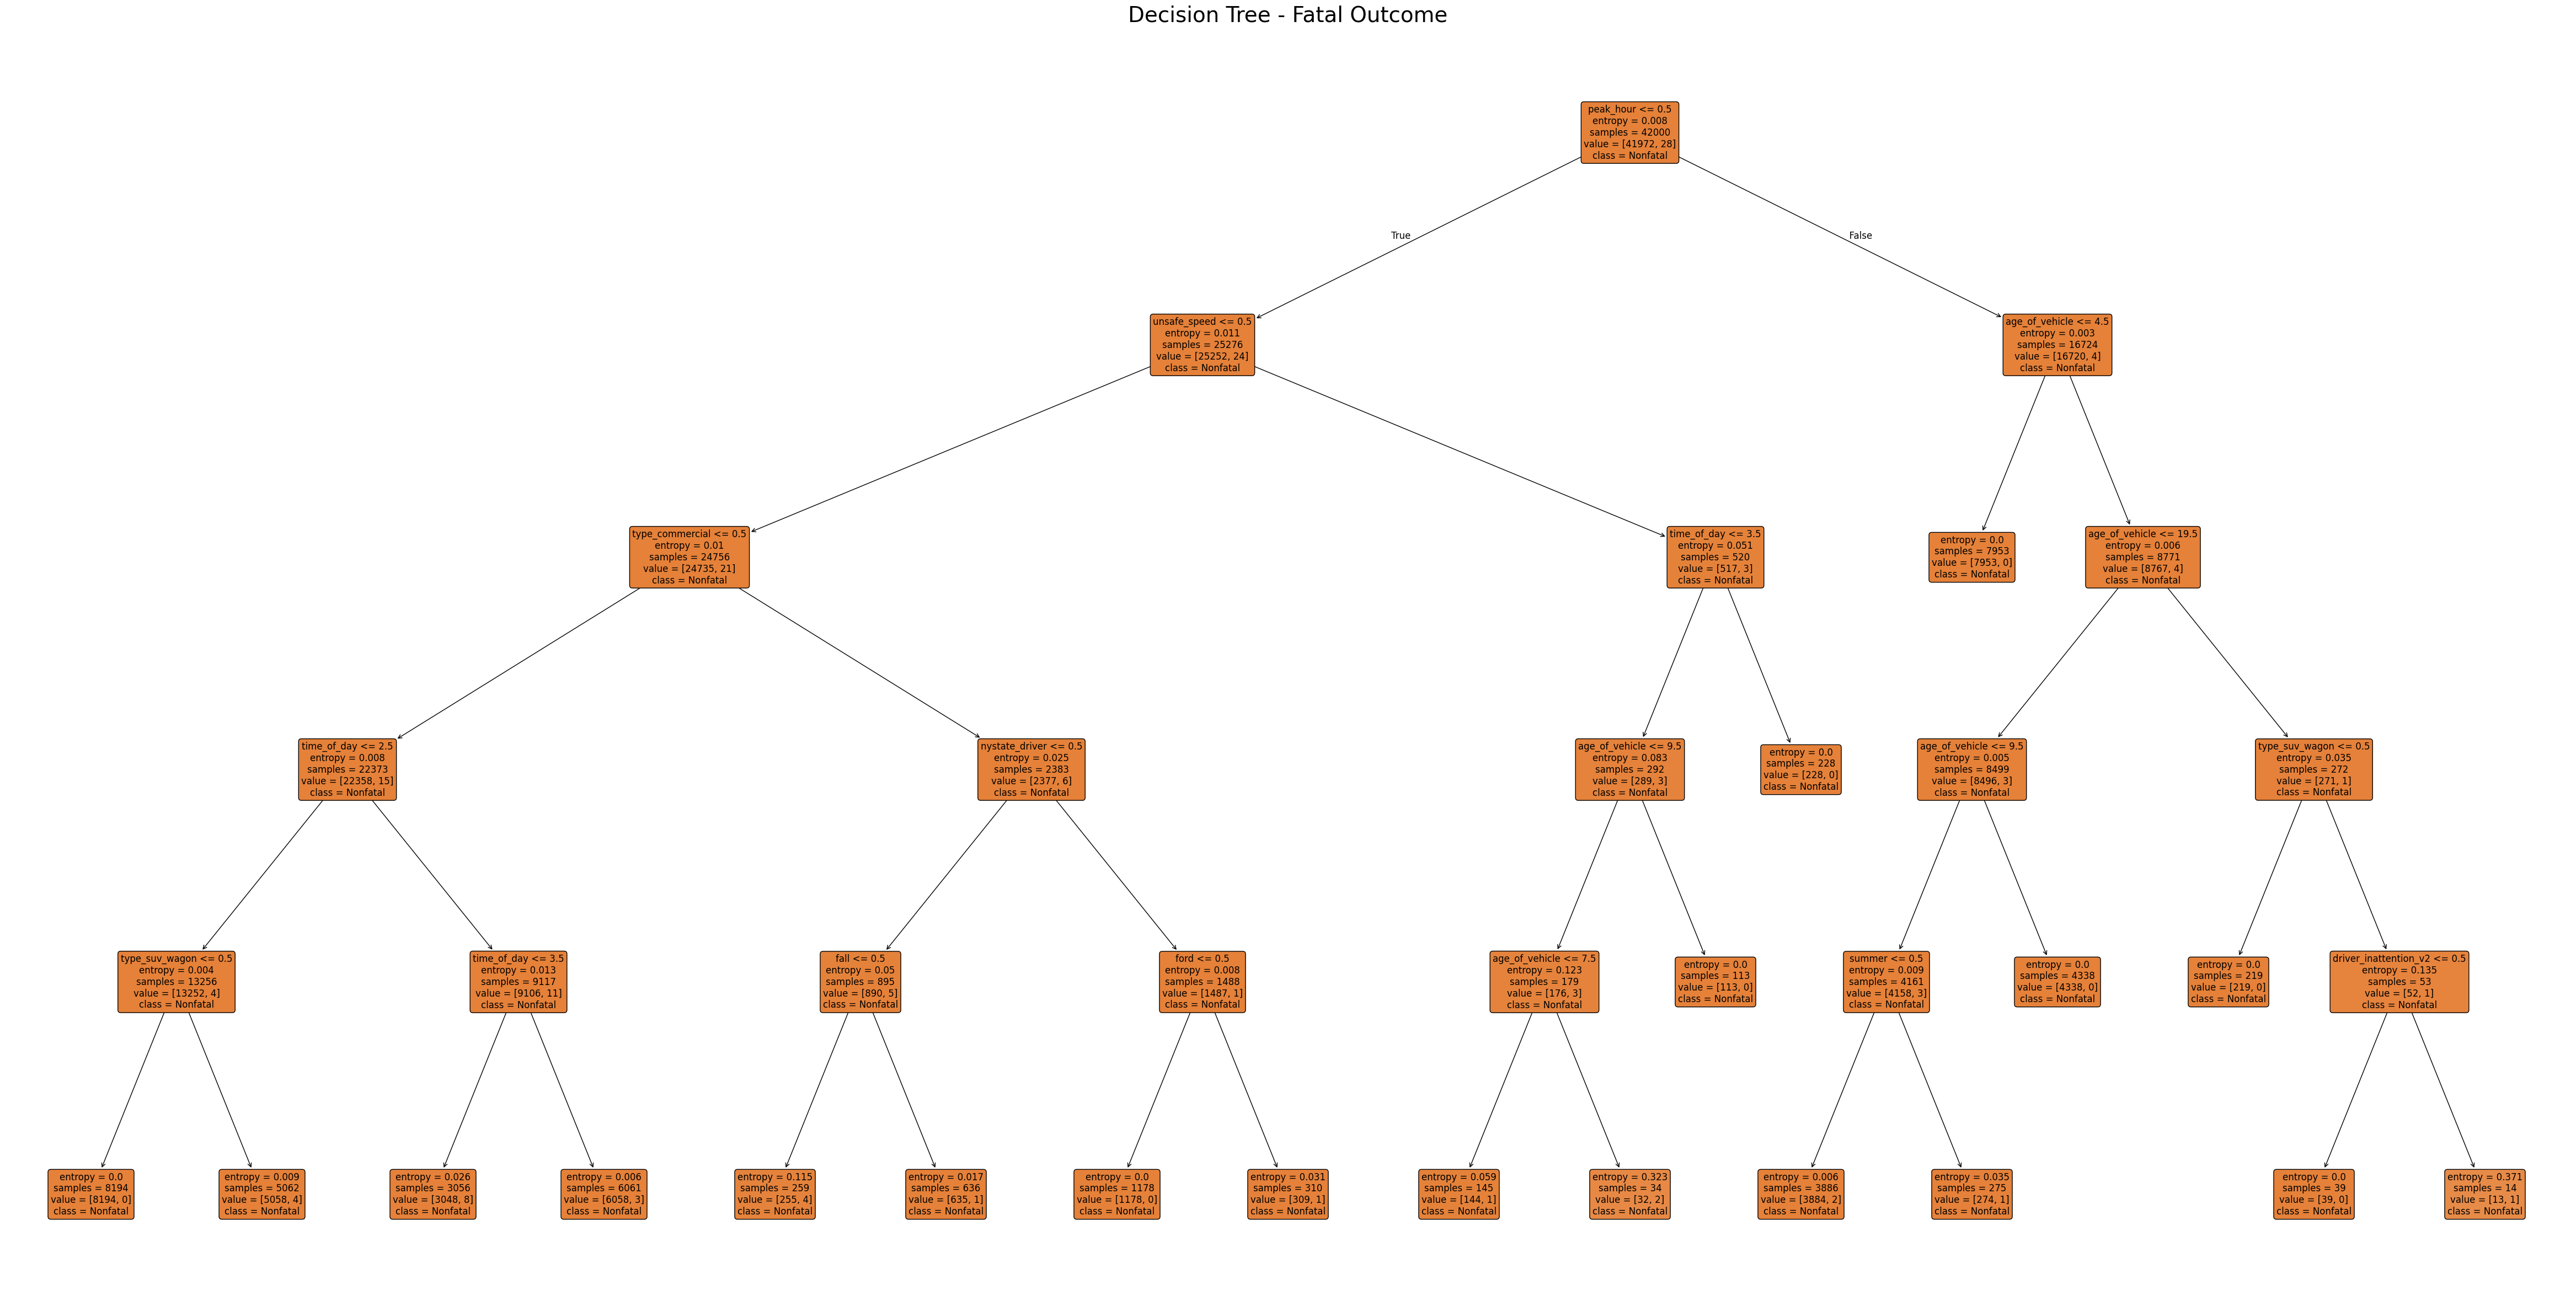

In [ ]:
# ----------------------------
# 13.1.5 Fatal decision tree
# ----------------------------
y_tree_fatal = df_model['fatal'].copy()

X_train_f, X_test_f, y_train_f, y_test_f = train_test_split(
    X_tree,
    y_tree_fatal,
    test_size=0.3,
    random_state=1,
    stratify=y_tree_fatal
)

tree_fatal = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_split=20,
    random_state=1
)

tree_fatal.fit(X_train_f, y_train_f)

pred_train_f = tree_fatal.predict(X_train_f)
pred_test_f = tree_fatal.predict(X_test_f)

print("\n===== DECISION TREE: FATAL OUTCOME =====")
print("Train accuracy:", accuracy_score(y_train_f, pred_train_f))
print("Test accuracy:", accuracy_score(y_test_f, pred_test_f))
print("Confusion matrix:")
print(confusion_matrix(y_test_f, pred_test_f))
print(classification_report(y_test_f, pred_test_f, zero_division=0))

plot_large_tree(
    model=tree_fatal,
    feature_names=tree_features,
    class_names=['Nonfatal', 'Fatal'],
    title='Decision Tree - Fatal Outcome',
    file_name='decision_tree_fatal_large.png'
)

Fatal Outcome Decision Tree

The fatal decision tree is dominated by the nonfatal class because fatal crashes are extremely rare. The first major split is based on unsafe speed, followed by commercial vehicle type, time of day, NY-state driver status, peak hour, and vehicle type controls. This supports the logit result that fatal crashes are better explained by crash severity conditions than by Ford alone.

In [ ]:
# ============================================================
# 13.2 Helper function: extra-large plot for injured tree
# ============================================================

def plot_injured_tree_large(model, feature_names, class_names, title, file_name):
    plt.figure(figsize=(90, 40))
    plot_tree(
        model,
        feature_names=feature_names,
        class_names=class_names,
        filled=True,
        rounded=True,
        fontsize=10,
        impurity=True,
        proportion=False
    )
    plt.title(title, fontsize=24)
    plt.savefig(file_name, dpi=300, bbox_inches='tight')
    plt.show()


===== DECISION TREE: INJURED OUTCOME =====
Train accuracy: 0.7714047619047619
Test accuracy: 0.7702222222222223
Confusion matrix:
[[13790    63]
 [ 4073    74]]
              precision    recall  f1-score   support

           0       0.77      1.00      0.87     13853
           1       0.54      0.02      0.03      4147

    accuracy                           0.77     18000
   macro avg       0.66      0.51      0.45     18000
weighted avg       0.72      0.77      0.68     18000



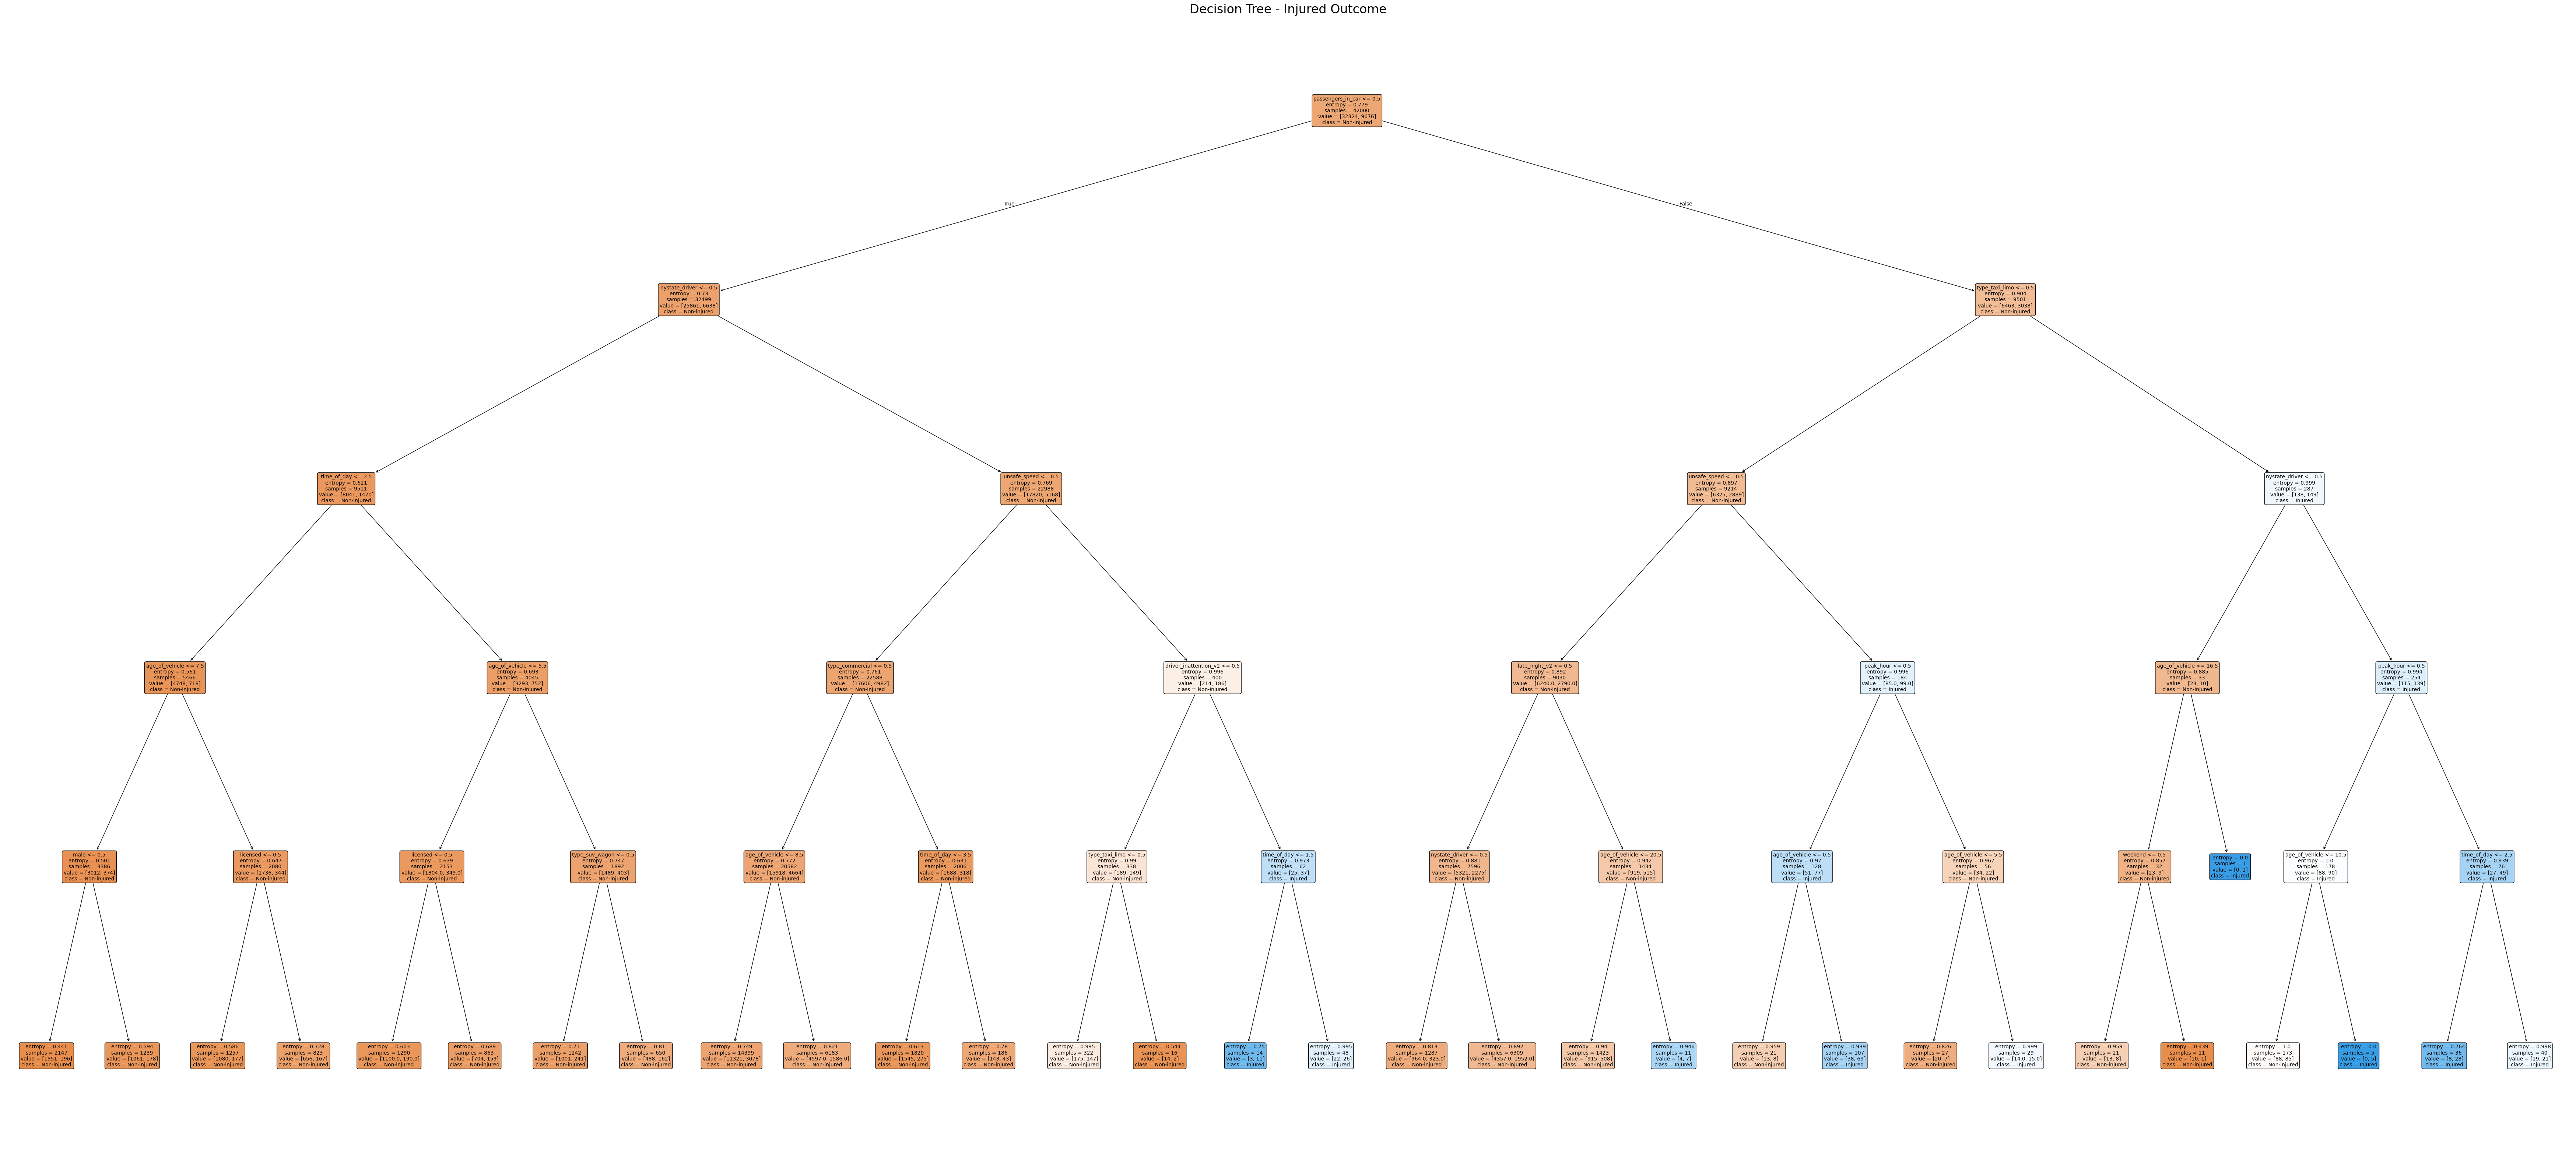

In [ ]:
# ----------------------------
# 13.2.1 Injured decision tree
# ----------------------------
y_tree_injured = df_model['injured'].copy()

X_train_i, X_test_i, y_train_i, y_test_i = train_test_split(
    X_tree,
    y_tree_injured,
    test_size=0.3,
    random_state=1,
    stratify=y_tree_injured
)

tree_injured = DecisionTreeClassifier(
    criterion='entropy',
    max_depth=5,
    min_samples_split=20,
    random_state=1
)

tree_injured.fit(X_train_i, y_train_i)

pred_train_i = tree_injured.predict(X_train_i)
pred_test_i = tree_injured.predict(X_test_i)

print("\n===== DECISION TREE: INJURED OUTCOME =====")
print("Train accuracy:", accuracy_score(y_train_i, pred_train_i))
print("Test accuracy:", accuracy_score(y_test_i, pred_test_i))
print("Confusion matrix:")
print(confusion_matrix(y_test_i, pred_test_i))
print(classification_report(y_test_i, pred_test_i, zero_division=0))

plot_injured_tree_large(
    model=tree_injured,
    feature_names=tree_features,
    class_names=['Non-injured', 'Injured'],
    title='Decision Tree - Injured Outcome',
    file_name='decision_tree_injured_large.png'
)

Injury Outcome Decision Tree

The injured decision tree is more informative than the fatal tree because injury cases are much more common. The main splits include NY-state driver status, time of day, unsafe speed, occupants, commercial vehicle type, older vehicles, driver inattention, and vehicle type. This confirms that injury outcomes are shaped by multiple driver, vehicle, and timing factors.

Across both logit regression and decision tree models, Ford is not the strongest predictor once controls are included. Unsafe speed, vehicle type, time of day, peak-hour status, occupancy, vehicle age, and driver behavior explain crash severity more consistently. The results suggest that crash outcomes depend more on driving conditions and vehicle characteristics than on Ford alone.